In [3]:
import matplotlib.pyplot as plt

import pandas as pd

In [4]:
sales = pd.read_csv("DB/retail_business_sales.csv")
sales

,sale_id,date,product,category,region,channel,price,unit_cost,quantity,discount_pct
0,S0001,2026-07-01,Desk organizer,Home,Bratislava,Online,16,6.00,4,5
1,S0002,2026-07-01,USB drive,Electronics,Zilina,Store,16,8.00,1,20
2,S0003,2026-07-01,Mouse,Electronics,Zilina,Online,25,14.00,3,20
3,S0004,2026-07-01,Lamp,Home,Kosice,Online,35,18.00,2,25
4,S0005,2026-07-01,Tote bag,Accessories,Kosice,Online,12,4.00,1,0
...,...,...,...,...,...,...,...,...,...,...
595,S0596,2026-09-30,Notebook,Stationery,Bratislava,Online,8,3.20,5,0
596,S0597,2026-09-30,Speaker,Electronics,Bratislava,Online,65,42.00,4,15
597,S0598,2026-09-30,Folder,Stationery,Kosice,Online,5,1.80,3,10
598,S0599,2026-09-30,Mug,Home,Kosice,Online,12,4.50,5,15


### in the following code i find revenue after discount which is 31490,5

In [5]:
rev_disc_sum = ((sales["price"]*(1 - sales["discount_pct"] / 100))*sales["quantity"]).sum()
print(rev_disc_sum)

31490.5


In [10]:
gross_profit = (((sales["price"]*(1 - sales["discount_pct"] / 100))*sales["quantity"]).sum() - (sales["unit_cost"] * sales["quantity"]).sum())
print(round(gross_profit, 2))

13038.85


In [11]:
total_sales_q = sales["quantity"].sum()
print(total_sales_q)

2199


In [6]:
sales["rev_disc"] = (sales["price"]*(1 - sales["discount_pct"] / 100))*sales["quantity"]
sales

,sale_id,date,product,category,region,channel,price,unit_cost,quantity,discount_pct,rev_disc
0,S0001,2026-07-01,Desk organizer,Home,Bratislava,Online,16,6.00,4,5,60.8
1,S0002,2026-07-01,USB drive,Electronics,Zilina,Store,16,8.00,1,20,12.8
2,S0003,2026-07-01,Mouse,Electronics,Zilina,Online,25,14.00,3,20,60.0
3,S0004,2026-07-01,Lamp,Home,Kosice,Online,35,18.00,2,25,52.5
4,S0005,2026-07-01,Tote bag,Accessories,Kosice,Online,12,4.00,1,0,12.0
...,...,...,...,...,...,...,...,...,...,...,...
595,S0596,2026-09-30,Notebook,Stationery,Bratislava,Online,8,3.20,5,0,40.0
596,S0597,2026-09-30,Speaker,Electronics,Bratislava,Online,65,42.00,4,15,221.0
597,S0598,2026-09-30,Folder,Stationery,Kosice,Online,5,1.80,3,10,13.5
598,S0599,2026-09-30,Mug,Home,Kosice,Online,12,4.50,5,15,51.0


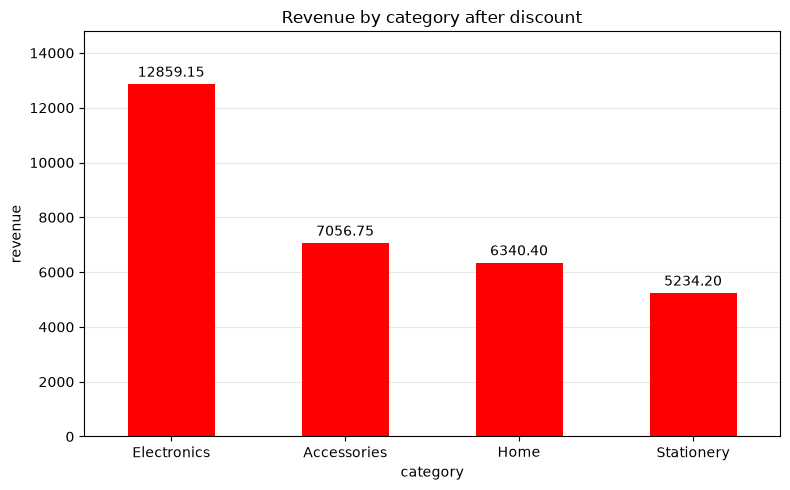

In [7]:
category_sales = (
    sales.groupby("category")["rev_disc"]
    .sum()
    .sort_values(ascending=False)
)
ax = category_sales.plot.bar(
    figsize = (8,5),
    title = "Revenue by category after discount",
    xlabel = "category",
    ylabel = "revenue",
    color = "red",
    rot = 0,
)
ax.bar_label(ax.containers[0], fmt="%.2f", padding=3)
ax.margins(y=0.15)
ax.set_axisbelow(True)
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [12]:
sales["net_profit"] = sales["rev_disc"] - sales["unit_cost"] * sales["quantity"]
sales

,sale_id,date,product,category,region,channel,price,unit_cost,quantity,discount_pct,rev_disc,net_profit
0,S0001,2026-07-01,Desk organizer,Home,Bratislava,Online,16,6.00,4,5,60.8,36.80
1,S0002,2026-07-01,USB drive,Electronics,Zilina,Store,16,8.00,1,20,12.8,4.80
2,S0003,2026-07-01,Mouse,Electronics,Zilina,Online,25,14.00,3,20,60.0,18.00
3,S0004,2026-07-01,Lamp,Home,Kosice,Online,35,18.00,2,25,52.5,16.50
4,S0005,2026-07-01,Tote bag,Accessories,Kosice,Online,12,4.00,1,0,12.0,8.00
...,...,...,...,...,...,...,...,...,...,...,...,...
595,S0596,2026-09-30,Notebook,Stationery,Bratislava,Online,8,3.20,5,0,40.0,24.00
596,S0597,2026-09-30,Speaker,Electronics,Bratislava,Online,65,42.00,4,15,221.0,53.00
597,S0598,2026-09-30,Folder,Stationery,Kosice,Online,5,1.80,3,10,13.5,8.10
598,S0599,2026-09-30,Mug,Home,Kosice,Online,12,4.50,5,15,51.0,28.50


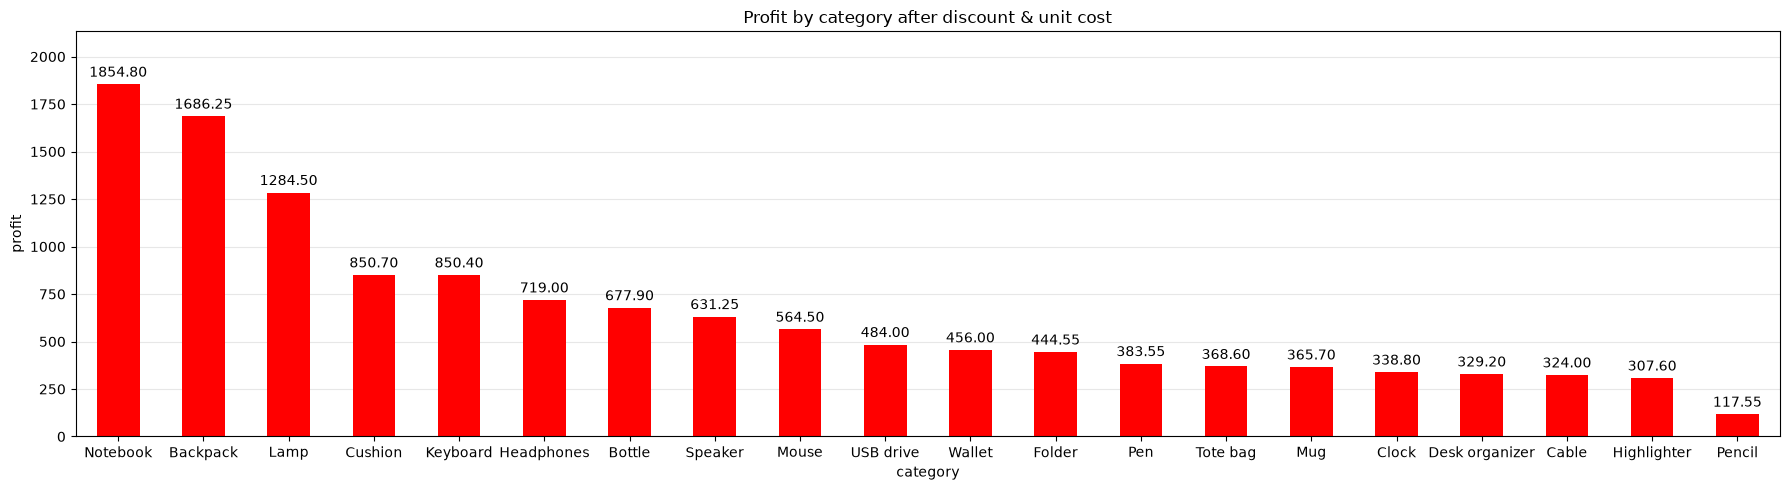

In [19]:
category_sales_net = (
    sales.groupby("product")["net_profit"]
    .sum()
    .sort_values(ascending=False)
)
ax = category_sales_net.plot.bar(
    figsize = (18,5),
    title = "Profit by category after discount & unit cost",
    xlabel = "category",
    ylabel = "profit",
    color = "red",
    rot = 0,
)
ax.bar_label(ax.containers[0], fmt="%.2f", padding=3)
ax.margins(y=0.15)
ax.set_axisbelow(True)
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

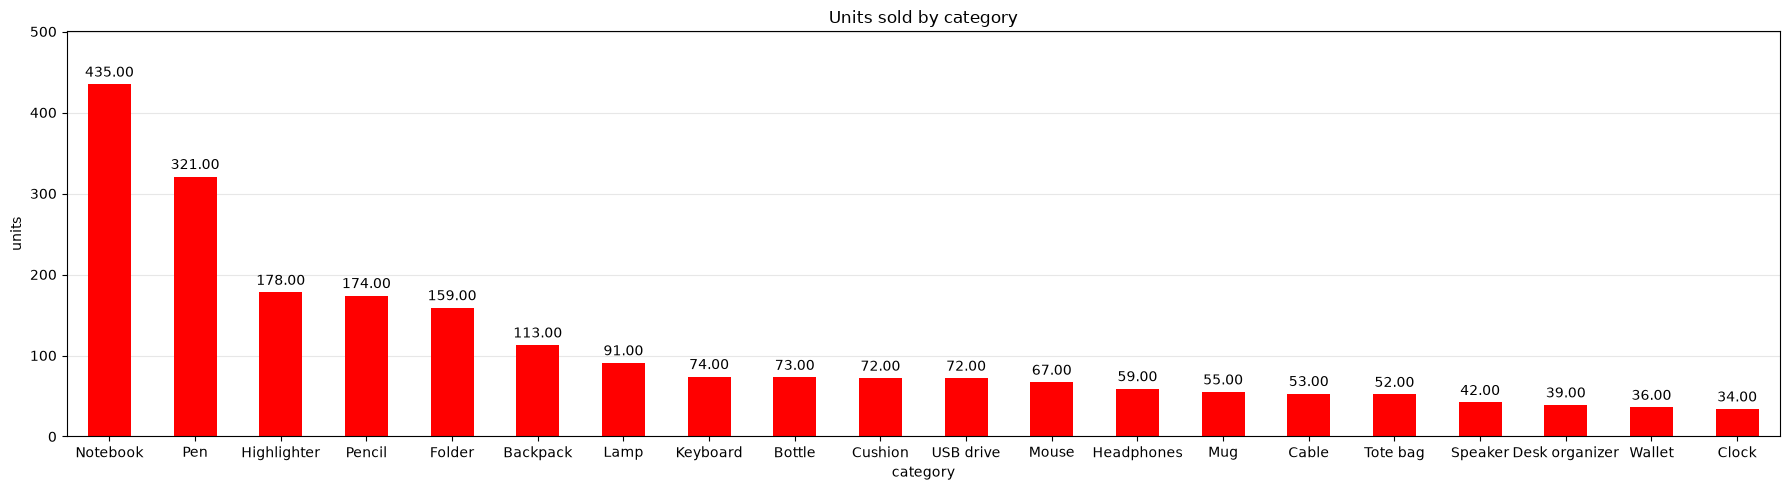

In [20]:
qunatity_sales_category = (
    sales.groupby("product")["quantity"]
    .sum()
    .sort_values(ascending=False)
)
ax = qunatity_sales_category.plot.bar(
    figsize = (18,5),
    title = "Units sold by category",
    xlabel = "category",
    ylabel = "units",
    color = "red",
    rot = 0,
)
ax.bar_label(ax.containers[0], fmt="%.2f", padding=3)
ax.margins(y=0.15)
ax.set_axisbelow(True)
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()